# Logistic regression: C 與交叉驗證 AUC

此 notebook 只讀取已完成的五組實驗，不重新訓練模型。

圖一：平均重複驗證 AUC ± 一個跨重複樣本標準差。
圖二：相同切分種子在不同 C 下的分數軌跡。

誤差棒描述資料切分的敏感程度，不是信賴區間。
所有分數均屬用於參數選擇的開發驗證結果。


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (current, *current.parents)
     if (path / "configs").is_dir() and (path / "outputs" / "results").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project directory.")

RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "regularization_study"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = [
    "baseline_logistic",
    "logistic_c_0_1",
    "logistic_c_0_01",
    "logistic_c_0_001",
    "logistic_c_0_0001",
]

print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification


In [2]:
records = []
reference_splits = None
reference_settings = None

for experiment_id in EXPERIMENTS:
    directory = RESULTS_DIR / experiment_id
    config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    summary = json.loads((directory / "summary.json").read_text(encoding="utf-8"))
    split_payload = json.loads((directory / "split_indices.json").read_text(encoding="utf-8"))
    repeats = pd.read_csv(directory / "repeat_scores.csv")

    settings = {
        key: config[key]
        for key in ["model_name", "max_iter", "n_splits", "split_seeds"]
    }
    if reference_settings is None:
        reference_settings = settings
        reference_splits = split_payload["splits"]
    elif settings != reference_settings or split_payload["splits"] != reference_splits:
        raise ValueError(f"Validation settings or splits differ: {experiment_id}")

    required = {"repeat", "split_seed", "mean_auc", "n_folds"}
    if not required.issubset(repeats.columns):
        raise ValueError(f"Missing repeat-score columns: {experiment_id}")
    if repeats[list(required)].isna().any().any():
        raise ValueError(f"Missing repeat-score values: {experiment_id}")
    if repeats["split_seed"].duplicated().any() or repeats["repeat"].duplicated().any():
        raise ValueError(f"Duplicate repetitions: {experiment_id}")
    if sorted(repeats["split_seed"].tolist()) != sorted(config["split_seeds"]):
        raise ValueError(f"Unexpected split seeds: {experiment_id}")
    if not repeats["n_folds"].eq(config["n_splits"]).all():
        raise ValueError(f"Unexpected fold count: {experiment_id}")
    if not repeats["mean_auc"].between(0, 1).all():
        raise ValueError(f"Invalid AUC: {experiment_id}")
    if summary["aggregation"] != "mean_fold_auc_per_repeat":
        raise ValueError(f"Unexpected aggregation: {experiment_id}")
    if not np.isclose(repeats["mean_auc"].mean(), summary["mean_auc"]):
        raise ValueError(f"Mean does not match summary: {experiment_id}")
    if not np.isclose(repeats["mean_auc"].std(ddof=1), summary["std_auc"]):
        raise ValueError(f"SD does not match summary: {experiment_id}")

    repeats = repeats.copy()
    repeats["C"] = config["regularization_c"]
    repeats["experiment_id"] = experiment_id
    records.append(repeats)

repeat_scores = pd.concat(records, ignore_index=True)
comparison = (
    repeat_scores.groupby("C", as_index=False)
    .agg(
        mean_auc=("mean_auc", "mean"),
        std_auc=("mean_auc", "std"),
        min_auc=("mean_auc", "min"),
        max_auc=("mean_auc", "max"),
        n_repeats=("mean_auc", "count"),
    )
    .sort_values("C")
    .reset_index(drop=True)
)

display(comparison.style.format({
    "C": "{:.4g}",
    "mean_auc": "{:.6f}",
    "std_auc": "{:.6f}",
    "min_auc": "{:.6f}",
    "max_auc": "{:.6f}",
}))


,C,mean_auc,std_auc,min_auc,max_auc,n_repeats
0,0.0001,0.790600,0.008026,0.780285,0.803216,10
1,0.001,0.793999,0.009091,0.779321,0.808694,10
2,0.01,0.792885,0.011157,0.775697,0.808673,10
3,0.1,0.771935,0.013106,0.757610,0.787983,10
4,1,0.751411,0.019922,0.723623,0.775493,10


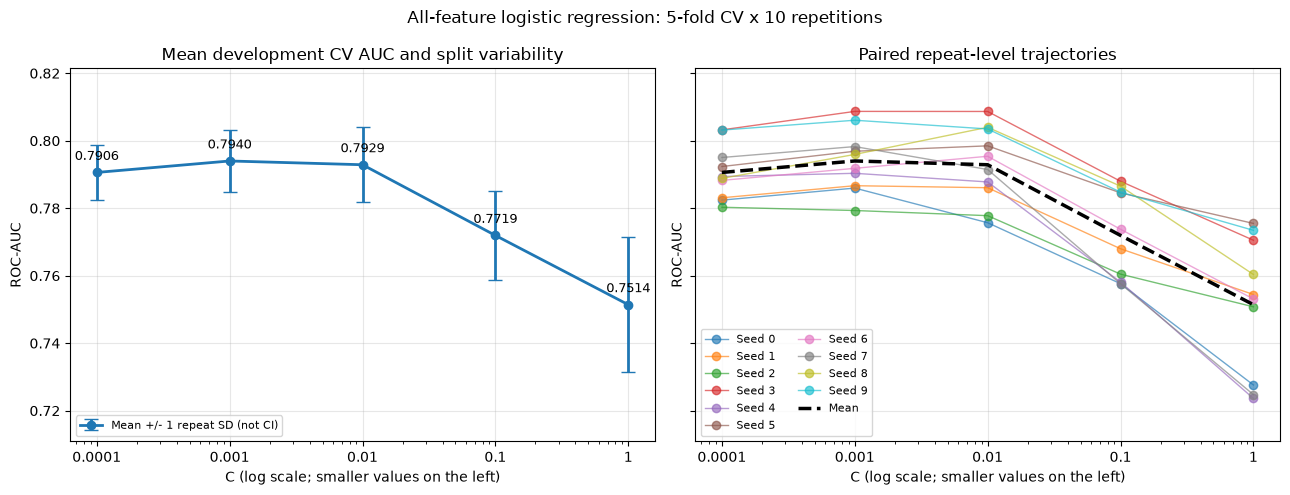

Figures and comparison table saved to: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification/outputs/figures/regularization_study


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
c_values = comparison["C"].to_numpy()

axes[0].errorbar(
    c_values,
    comparison["mean_auc"],
    yerr=comparison["std_auc"],
    fmt="o-",
    color="tab:blue",
    linewidth=2,
    capsize=5,
    label="Mean +/- 1 repeat SD (not CI)",
)

for row in comparison.itertuples(index=False):
    axes[0].annotate(
        f"{row.mean_auc:.4f}",
        (row.C, row.mean_auc),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

axes[0].set_title("Mean development CV AUC and split variability")
axes[0].legend(fontsize=8, loc="lower left")

for seed, group in repeat_scores.groupby("split_seed"):
    group = group.sort_values("C")
    axes[1].plot(
        group["C"], group["mean_auc"],
        marker="o", linewidth=1, alpha=0.65,
        label=f"Seed {seed}",
    )

axes[1].plot(
    comparison["C"], comparison["mean_auc"],
    color="black", linestyle="--", linewidth=2.5,
    label="Mean",
)
axes[1].set_title("Paired repeat-level trajectories")
axes[1].legend(fontsize=8, ncol=2, loc="lower left")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(c_values)
    ax.set_xticklabels([f"{value:g}" for value in c_values])
    ax.set_xlabel("C (log scale; smaller values on the left)")
    ax.set_ylabel("ROC-AUC")
    ax.grid(True, which="major", alpha=0.3)
    ax.margins(y=0.15)

fig.suptitle("All-feature logistic regression: 5-fold CV x 10 repetitions")
fig.tight_layout()

fig.savefig(FIGURES_DIR / "c_vs_auc.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURES_DIR / "c_vs_auc.pdf", bbox_inches="tight")
comparison.to_csv(FIGURES_DIR / "c_comparison.csv", index=False)

plt.show()
print(f"Figures and comparison table saved to: {FIGURES_DIR}")


## 解讀時要注意

- 左圖的點是十次重複驗證的平均值，誤差棒是它們的樣本標準差。
- 右圖每條彩色線對應相同 split seed，有助於觀察改善是否一致。
- 橫軸由左至右是 C 由小到大，不是實驗執行順序。
- 兩圖的 Y 軸依結果自動縮放，不一定從零開始；不要誇大微小差距。
- 折線只連接已測試的設定，不代表中間未測試值的真實表現。
- split JSON 一致只確認索引相同，仍需資料雜湊和程式版本才能確認整個比較完全一致。
- 此 notebook 不重新訓練，不改動原本實驗結果。
